# NYC Yellow Taxi EDA: all records retained
**Negar Kamvij — CS672 Project 1**

## Project objective
> Perform an explanatory data analysis (EDA) on NYC’s Yellow Taxi Trip Records from 2020. Although there will be no need to build a model based on the data provided, you are asked to look for issues in the data and find correlation among the various variables to improve ride time predictions.

This project uses March 2020 as the reference dataset and May 2020 as the evaluation dataset. January 2020 is the baseline for the extra-credit comparison. **All original rows are kept, and possible data problems are flagged.** Durations above 180 minutes and distances above 100 miles are warning thresholds. These records are not deleted. No prediction model is trained in this project.

Source: assignment page 1 and [NYC TLC trip records](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page). The setup cell downloads missing January, March, and May Yellow Taxi Parquet files from the official TLC source into `data/`. Existing files are reused. GraphViz needs the system `dot` executable. Dependencies: pandas, NumPy, PyArrow, Matplotlib, seaborn, tensorflow-data-validation, apache-beam, and graphviz.


## Setup and running the notebook
Run the cells in order in a Python environment with the listed libraries installed. The saved outputs allow the analysis to be read without running it again. A full run loads millions of records and needs enough memory and disk space. Internet access is needed if data files are missing.

If Python packages are missing, run the following in a separate notebook cell, then restart the kernel:
```python
%pip install pandas numpy pyarrow matplotlib seaborn tensorflow-data-validation apache-beam graphviz
```
GraphViz also needs the system `dot` program. On Colab, install it with `!apt-get -qq install graphviz`. On macOS, use `brew install graphviz`. TFDV needs an environment compatible with its dependencies; package installation alone is not a guarantee of compatibility.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from importlib.metadata import version
import shutil, subprocess
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
from urllib.request import urlretrieve

def ensure_taxi_file(month_number: int) -> Path:
    """Return a monthly TLC file path, downloading the file only if missing.

    Args:
        month_number (int): Month in 2020, from 1 through 12.
    Returns:
        Path: Local Parquet file containing the original monthly records.
    Raises:
        ValueError: If the month is outside 1 through 12.
        OSError: If the download or local file operation fails.
    """
    if not 1 <= month_number <= 12:
        raise ValueError("month_number must be between 1 and 12")
    destination = DATA_DIR / f"yellow_tripdata_2020-{month_number:02d}.parquet"
    if not destination.exists():
        temporary = destination.with_suffix(".parquet.part")
        url = f"https://d37ci6vzurychx.cloudfront.net/trip-data/{destination.name}"
        print("Downloading", destination.name)
        urlretrieve(url, temporary)
        temporary.replace(destination)
    print("Available:", destination.name)
    return destination

for month_number in [1, 3, 5]:
    ensure_taxi_file(month_number)
sns.set_theme(style="whitegrid", palette=["#FFC31D", "#107E68"])
for name in ["pandas", "numpy", "tensorflow-data-validation", "apache-beam", "graphviz"]:
    print(name, version(name))
print(subprocess.check_output(["dot", "-V"], stderr=subprocess.STDOUT, text=True).strip())


Available: yellow_tripdata_2020-01.parquet
Available: yellow_tripdata_2020-03.parquet
Available: yellow_tripdata_2020-05.parquet
pandas 2.3.3
numpy 2.4.6
tensorflow-data-validation 1.21.0
apache-beam 2.77.0
graphviz 0.21
dot - graphviz version 16.1.0 (20260904.0139)


## 1. Data preparation: keeping all records
The original columns are kept. I convert the pickup and drop-off times to datetime values, calculate trip duration, and add True/False flags for possible data problems. All rows are kept. A long trip is not always an error.


In [2]:
def prepare_records(frame: pd.DataFrame, month_number: int) -> pd.DataFrame:
    """Return a copy with derived features and quality flags; retain every row.

    Args:
        frame (pd.DataFrame): Taxi records with pickup/drop-off timestamps,
            trip_distance, and passenger_count.
        month_number (int): Expected 2020 pickup month, from 1 through 12.

    Returns:
        pd.DataFrame: All original rows and fields, plus parsed timestamps,
        duration, pickup-time features, and independent quality flags.

    Raises:
        KeyError: If a required source column is absent.

    Notes:
        Thresholds flag rides for investigation. No records are deleted.
        The input is not modified. Month validity is assumed.
    """
    result = frame.copy()
    pickup = pd.to_datetime(result["tpep_pickup_datetime"], errors="coerce")
    dropoff = pd.to_datetime(result["tpep_dropoff_datetime"], errors="coerce")
    duration = (dropoff - pickup).dt.total_seconds() / 60
    result["parsed_pickup"] = pickup
    result["parsed_dropoff"] = dropoff
    result["trip_duration_minutes"] = duration
    result["pickup_hour"] = pickup.dt.hour
    result["pickup_day_of_week"] = pickup.dt.dayofweek
    result["flag_missing_timestamp"] = pickup.isna() | dropoff.isna()
    result["flag_outside_pickup_month"] = ~(pickup.dt.year.eq(2020) & pickup.dt.month.eq(month_number))
    result["flag_nonpositive_duration"] = duration.le(0)
    result["flag_nonfinite_duration"] = ~np.isfinite(duration)
    result["flag_long_duration"] = duration.gt(180)
    result["flag_zero_or_negative_distance"] = result["trip_distance"].le(0)
    result["flag_nonfinite_distance"] = ~np.isfinite(result["trip_distance"])
    result["flag_long_distance"] = result["trip_distance"].gt(100)
    result["flag_missing_passenger_count"] = result["passenger_count"].isna()
    assert len(result) == len(frame)
    assert result.index.equals(frame.index)
    return result

records = {}
source_counts = {}
for month, month_number in [("March", 3), ("May", 5)]:
    source = pd.read_parquet(DATA_DIR / f"yellow_tripdata_2020-{month_number:02d}.parquet")
    source_counts[month] = len(source)
    records[month] = prepare_records(source, month_number)
    print(month, "source rows:", len(source), "retained rows:", len(records[month]))
    display(source.head())
    print("Exact duplicate rows:", source.duplicated().sum())
    display(pd.DataFrame({"dtype": source.dtypes.astype(str), "missing_count": source.isna().sum(), "missing_percent": source.isna().mean()*100}))
    del source


March source rows: 3007687 retained rows: 3007687
Exact duplicate rows: 0
May source rows: 348415 retained rows: 348415
Exact duplicate rows: 0


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,1,2020-03-01 00:31:13,2020-03-01 01:01:42,1.0,4.70,1.0,N,88,255,1,22.0,3.0,0.5,2.00,0.0,0.3,27.80,2.5,None
1,2,2020-03-01 00:08:22,2020-03-01 00:08:49,1.0,0.00,1.0,N,193,193,2,2.5,0.5,0.5,0.00,0.0,0.3,3.80,0.0,None
2,1,2020-03-01 00:52:18,2020-03-01 00:59:16,1.0,1.10,1.0,N,246,90,1,6.0,3.0,0.5,1.95,0.0,0.3,11.75,2.5,None
3,2,2020-03-01 00:47:53,2020-03-01 00:50:57,2.0,0.87,1.0,N,151,238,1,5.0,0.5,0.5,1.76,0.0,0.3,10.56,2.5,None
4,1,2020-03-01 00:43:19,2020-03-01 00:58:27,0.0,4.40,1.0,N,79,261,1,16.5,3.0,0.5,4.05,0.0,0.3,24.35,2.5,None


,dtype,missing_count,missing_percent
VendorID,int64,0,0.000000
tpep_pickup_datetime,datetime64[us],0,0.000000
tpep_dropoff_datetime,datetime64[us],0,0.000000
passenger_count,float64,37808,1.257046
trip_distance,float64,0,0.000000
RatecodeID,float64,37808,1.257046
store_and_fwd_flag,object,37808,1.257046
PULocationID,int64,0,0.000000
DOLocationID,int64,0,0.000000
payment_type,int64,0,0.000000


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,1,2020-05-01 00:02:28,2020-05-01 00:18:07,1.0,0.0,1.0,N,234,256,1,12.2,3.0,0.5,2.4,0.0,0.3,18.4,2.5,None
1,1,2020-05-01 00:23:21,2020-05-01 00:26:01,2.0,0.4,1.0,N,264,264,1,4.0,0.5,0.5,0.5,0.0,0.3,5.8,0.0,None
2,1,2020-05-01 00:54:58,2020-05-01 00:57:11,1.0,0.3,1.0,N,264,264,2,3.5,0.5,0.5,0.0,0.0,0.3,4.8,0.0,None
3,1,2020-05-01 00:07:10,2020-05-01 00:12:46,1.0,1.7,1.0,N,107,229,2,7.0,3.0,0.5,0.0,0.0,0.3,10.8,2.5,None
4,1,2020-05-01 00:55:47,2020-05-01 01:01:54,0.0,0.9,1.0,N,237,262,1,6.0,3.0,0.5,1.2,0.0,0.3,11.0,2.5,None


,dtype,missing_count,missing_percent
VendorID,int64,0,0.000000
tpep_pickup_datetime,datetime64[us],0,0.000000
tpep_dropoff_datetime,datetime64[us],0,0.000000
passenger_count,float64,58901,16.905415
trip_distance,float64,0,0.000000
RatecodeID,float64,58901,16.905415
store_and_fwd_flag,object,58901,16.905415
PULocationID,int64,0,0.000000
DOLocationID,int64,0,0.000000
payment_type,int64,0,0.000000


## 2. Data types and quality checks

| Data type | Original fields |
| --- | --- |
| Datetime | Pickup and drop-off timestamps |
| Numeric count/distance | Passenger count and trip distance |
| Numeric monetary fields | Fare, extra, taxes, tip, tolls, surcharges, total, airport fee |
| Categorical numeric codes | Vendor, rate code, pickup/drop-off zone IDs, payment type |
| Categorical text | Store-and-forward flag |

Numeric IDs identify categories. They do not represent measured amounts. Airport fee is completely missing in these March/May files. I keep it in the retained source data but exclude it from the selected numeric inputs. One trip can have more than one flag, so the flag counts should not be added to get a total number of trips.


In [3]:
flag_columns = [c for c in records["March"].columns if c.startswith("flag_")]
quality_audit = pd.DataFrame({month: frame[flag_columns].sum() for month, frame in records.items()})
display(quality_audit)
retention_audit = pd.DataFrame({month: {"source_rows": source_counts[month], "retained_rows": len(frame), "removed_rows": source_counts[month] - len(frame)} for month, frame in records.items()}).T
display(retention_audit)
assert retention_audit["removed_rows"].eq(0).all()
for month, frame in records.items():
    print(month)
    display(frame[["trip_duration_minutes", "trip_distance", "passenger_count"]].describe(percentiles=[.01,.5,.95,.99]))
    display(frame.nlargest(3, "trip_distance")[["trip_distance", "trip_duration_minutes"]])


March
May


,March,May
flag_missing_timestamp,0,0
flag_outside_pickup_month,426,23
flag_nonpositive_duration,2131,630
flag_nonfinite_duration,0,0
flag_long_duration,5904,465
flag_zero_or_negative_distance,31396,10226
flag_nonfinite_distance,0,0
flag_long_distance,28,40
flag_missing_passenger_count,37808,58901


,source_rows,retained_rows,removed_rows
March,3007687,3007687,0
May,348415,348415,0


,trip_duration_minutes,trip_distance,passenger_count
count,3.007687e+06,3.007687e+06,2.969879e+06
mean,1.558840e+01,3.117041e+00,1.467477e+00
std,6.558050e+01,2.069207e+02,1.120087e+00
min,-4.746262e+04,0.000000e+00,0.000000e+00
1%,9.000000e-01,0.000000e+00,0.000000e+00
50%,1.040000e+01,1.670000e+00,1.000000e+00
95%,3.276667e+01,1.023000e+01,5.000000e+00
99%,5.436667e+01,1.888000e+01,6.000000e+00
max,1.814817e+03,2.698037e+05,9.000000e+00


,trip_distance,trip_duration_minutes
2973275,269803.73,16.0
2978212,210148.62,106.0
2984809,70137.72,23.0


,trip_duration_minutes,trip_distance,passenger_count
count,348415.000000,348415.000000,289514.000000
mean,13.510946,8.333053,1.314171
std,47.169801,774.817906,0.983983
min,-0.333333,0.000000,0.000000
1%,0.366667,0.000000,0.000000
50%,8.950000,1.990000,1.000000
95%,32.000000,13.500000,3.000000
99%,47.000000,21.110000,6.000000
max,1438.866667,297004.510000,9.000000


,trip_distance,trip_duration_minutes
291788,297004.51,27.0
310208,148342.26,32.0
328045,130587.13,121.0


## 3. Exploratory data analysis
The duration chart places each record in one group. The groups include zero or negative durations, very long durations, and missing durations. The chart shows the share of records in each group. The groups have different widths, so the chart is not a density plot. Correlations use pairs with available numeric values. If a timestamp is missing or cannot be read, duration cannot be calculated. The original row is still kept.


,March,May
<=0,0.000709,0.001808
0–5,0.168574,0.237751
5–10,0.310171,0.317191
10–15,0.216563,0.180136
15–20,0.127040,0.100507
20–30,0.112326,0.102335
30–60,0.057454,0.056381
60–180,0.005202,0.002557
>180,0.001963,0.001335
Missing,0.000000,0.000000


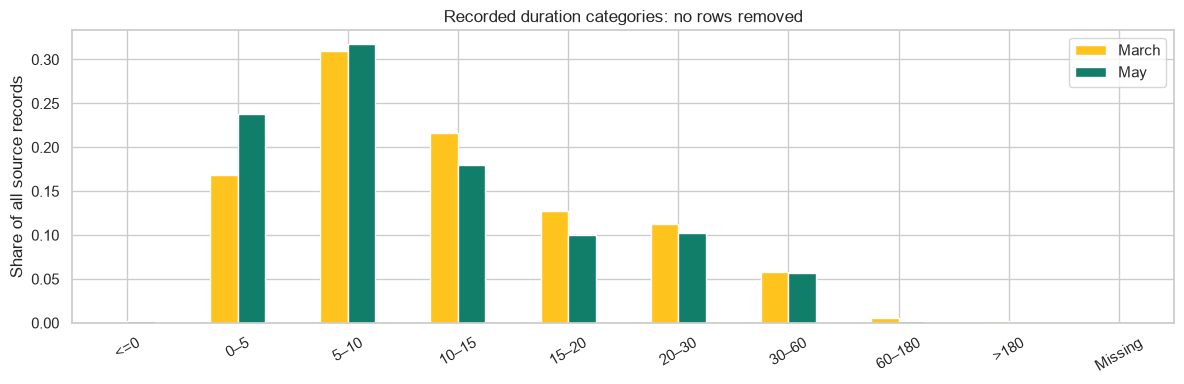

,trip_distance,passenger_count,pickup_hour,pickup_day_of_week,trip_duration_minutes
trip_distance,1.000000,0.020811,0.025715,0.011632,0.847030
passenger_count,0.020811,1.000000,0.033160,0.044679,0.020606
pickup_hour,0.025715,0.033160,1.000000,-0.039338,0.029537
pickup_day_of_week,0.011632,0.044679,-0.039338,1.000000,-0.045546
trip_duration_minutes,0.847030,0.020606,0.029537,-0.045546,1.000000


In [4]:
duration_labels = ["<=0", "0–5", "5–10", "10–15", "15–20", "20–30", "30–60", "60–180", ">180", "Missing"]
def duration_shares(frame: pd.DataFrame) -> list[float]:
    """Return proportions of all rows across exhaustive duration categories.

    Args:
        frame (pd.DataFrame): Retained records with trip_duration_minutes.

    Returns:
        list[float]: Shares for nonpositive, positive duration bins,
        and missing durations, in duration_labels order. Shares sum to one.
    """
    d = frame["trip_duration_minutes"]
    masks = [d.le(0)] + [(d.gt(a) & d.le(b)) for a,b in [(0,5),(5,10),(10,15),(15,20),(20,30),(30,60),(60,180)]] + [d.gt(180), d.isna()]
    shares = [float(mask.sum()/len(frame)) for mask in masks]
    assert np.isclose(sum(shares), 1)
    return shares

duration_table = pd.DataFrame({month: duration_shares(frame) for month, frame in records.items()}, index=duration_labels)
display(duration_table)
duration_table.plot.bar(figsize=(12,4), rot=30)
plt.ylabel("Share of all source records")
plt.title("Recorded duration categories: no rows removed")
plt.tight_layout(); plt.show()
features = ["trip_distance", "passenger_count", "pickup_hour", "pickup_day_of_week"]
correlation_table = records["March"][features + ["trip_duration_minutes"]].corr(method="spearman")
display(correlation_table)


Display range is limited for readability; records outside it remain in the dataset and summaries.


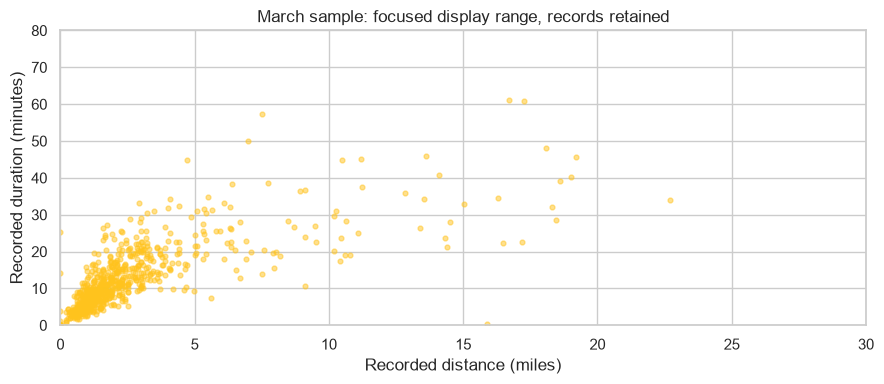

In [5]:
march_sample = records["March"].sample(n=700, random_state=42)
plt.figure(figsize=(9,4))
plt.scatter(march_sample["trip_distance"], march_sample["trip_duration_minutes"], s=12, alpha=.5)
plt.xlim(0,30); plt.ylim(0,80)
plt.xlabel("Recorded distance (miles)"); plt.ylabel("Recorded duration (minutes)")
plt.title("March sample: focused display range, records retained")
plt.tight_layout(); plt.show()
print("Display range is limited for readability; records outside it remain in the dataset and summaries.")


## 4. March and May comparison
Counts refer to the monthly files, including records flagged as outside the intended pickup month. Numerical medians describe the recorded values, including suspicious finite values. These summaries do not mean that every record is a valid completed trip. The flags help identify records that need more investigation.


,all_source_records,median_recorded_duration_minutes,mean_recorded_duration_minutes,median_recorded_distance_miles,passenger_missing_percent
March,3007687.0,10.40,15.588400,1.67,1.257046
May,348415.0,8.95,13.510946,1.99,16.905415


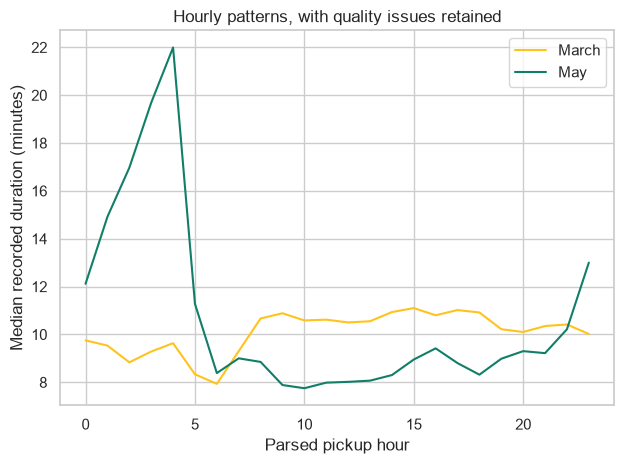

In [6]:
summary = pd.DataFrame({month: {
    "all_source_records": len(frame),
    "median_recorded_duration_minutes": frame["trip_duration_minutes"].median(),
    "mean_recorded_duration_minutes": frame["trip_duration_minutes"].mean(),
    "median_recorded_distance_miles": frame["trip_distance"].median(),
    "passenger_missing_percent": frame["passenger_count"].isna().mean()*100,
} for month, frame in records.items()}).T
display(summary)
for month, frame in records.items():
    frame.groupby("pickup_hour")["trip_duration_minutes"].median().plot(label=month)
plt.xlabel("Parsed pickup hour"); plt.ylabel("Median recorded duration (minutes)")
plt.title("Hourly patterns, with quality issues retained"); plt.legend();plt.tight_layout();plt.show()


## 5. TensorFlow Data Validation (TFDV) comparison
I reset the index to avoid treating row numbers as features. I generate statistics from all retained March/May rows, for the selected numeric features. The schema describes the structure of the March reference data, which still has data-quality problems. A successful validation does not mean that every record is correct. No statistical drift threshold is set in this analysis.


In [7]:
import tensorflow_data_validation as tfdv
validation_columns = features + ["trip_duration_minutes"]
train_stats = tfdv.generate_statistics_from_dataframe(records["March"][validation_columns].reset_index(drop=True))
eval_stats = tfdv.generate_statistics_from_dataframe(records["May"][validation_columns].reset_index(drop=True))
tfdv.visualize_statistics(train_stats, eval_stats, lhs_name="March: all records", rhs_name="May: all records")
schema = tfdv.infer_schema(train_stats)
tfdv.display_schema(schema)
anomalies = tfdv.validate_statistics(eval_stats, schema)
tfdv.display_anomalies(anomalies)
print("Schema anomaly count:", len(anomalies.anomaly_info))


Schema anomaly count: 0


,Type,Presence,Valency,Domain
Feature name,,,,
'trip_distance',FLOAT,required,,-
'passenger_count',FLOAT,optional,single,-
'pickup_hour',INT,required,,-
'pickup_day_of_week',INT,required,,-
'trip_duration_minutes',FLOAT,required,,-


## 6. Numeric inputs: keeping the original data
I keep the original records and targets intact. For a separate numeric input copy, I replace missing or infinite input values with March medians and apply the same values to May. Numeric flag columns are available for quality inspection, but flags based on trip duration are not prediction inputs because they would reveal information about the value being predicted.

I retain every target value, including missing or nonpositive duration, and provide a True/False indicator for whether the target can be used. This indicator can help with future model preparation; no model is trained and no rows are deleted. A numeric input table alone does not make the source data error-free. Recorded distance is a post-trip value and would need an estimate in a real pickup-time prediction.


In the separate numeric inputs, negative distances and negative passenger counts are marked as missing before filling. Long trips are kept. Invalid durations are not filled with invented target values; the target-availability indicator marks them for a future modeling decision. No model-ready claim is made for the original raw records.

In [8]:
train_inputs = records["March"][features].replace([np.inf,-np.inf], np.nan)
train_inputs["trip_distance"] = train_inputs["trip_distance"].where(train_inputs["trip_distance"].ge(0))
train_inputs["passenger_count"] = train_inputs["passenger_count"].where(train_inputs["passenger_count"].ge(0))
fill_values = train_inputs.median()
X_train = train_inputs.fillna(fill_values).astype(float)
eval_inputs = records["May"][features].replace([np.inf,-np.inf], np.nan)
eval_inputs["trip_distance"] = eval_inputs["trip_distance"].where(eval_inputs["trip_distance"].ge(0))
eval_inputs["passenger_count"] = eval_inputs["passenger_count"].where(eval_inputs["passenger_count"].ge(0))
X_eval = eval_inputs.fillna(fill_values).astype(float)
y_train = records["March"]["trip_duration_minutes"].copy()
y_eval = records["May"]["trip_duration_minutes"].copy()
target_available = {month: np.isfinite(frame["trip_duration_minutes"]) & frame["trip_duration_minutes"].gt(0) for month, frame in records.items()}
quality_flags = {month: frame[flag_columns].astype("int8") for month, frame in records.items()}
assert len(X_train)==source_counts["March"] and len(X_eval)==source_counts["May"]
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_eval.to_numpy()).all()
print("Training inputs:", X_train.shape, "Evaluation inputs:", X_eval.shape)
display(fill_values.to_frame("March input fill value"))
print("Rows removed: 0. Targets and quality flags remain available separately.")


Training inputs: (3007687, 4) Evaluation inputs: (348415, 4)
Rows removed: 0. Targets and quality flags remain available separately.


,March input fill value
trip_distance,1.67
passenger_count,1.00
pickup_hour,14.00
pickup_day_of_week,3.00


## 7. Extra credit: January baseline
I read every January row for the four fields needed for the baseline comparison. Column selection reduces memory use; it does not sample or filter records. I apply the same flagging function, with January as the expected month.


Outside-month/invalid pickups remain in the datasets and baseline totals; their counts are shown above.


,all_source_records,records_per_31_calendar_days,median_recorded_duration_minutes,median_recorded_distance_miles,flagged_outside_pickup_month
January,6405008.0,206613.16129,10.483333,1.60,212.0
March,3007687.0,97022.16129,10.400000,1.67,426.0


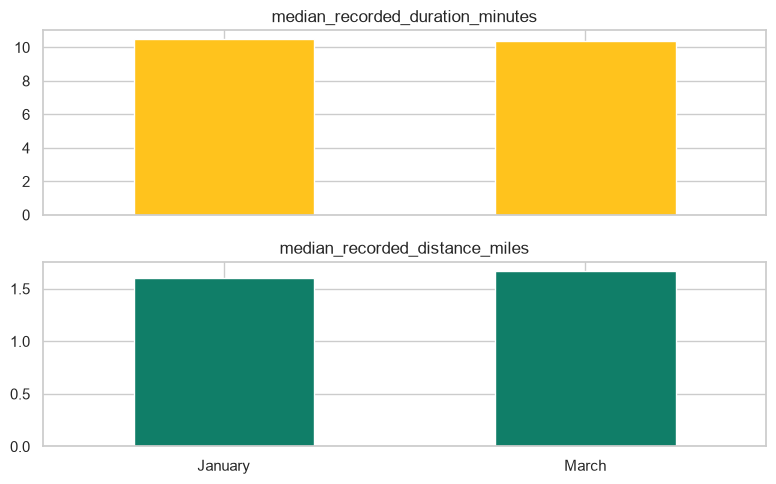

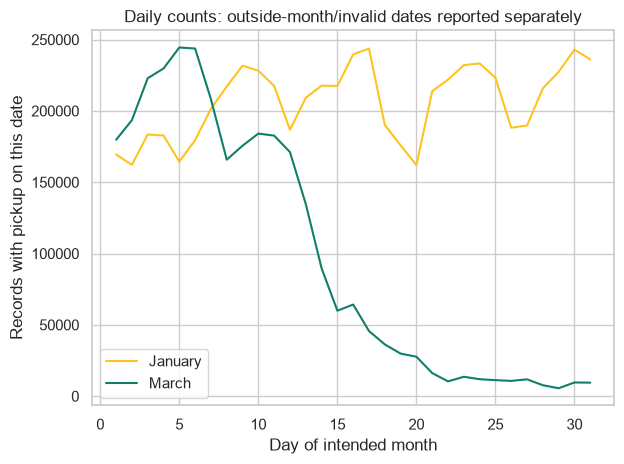

In [9]:
january = pd.read_parquet(DATA_DIR / "yellow_tripdata_2020-01.parquet", columns=["tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance", "passenger_count"])
source_counts["January"] = len(january)
records["January"] = prepare_records(january, 1)
del january
assert len(records["January"])==source_counts["January"]
baseline = pd.DataFrame({month: {
    "all_source_records": len(records[month]),
    "records_per_31_calendar_days": len(records[month])/31,
    "median_recorded_duration_minutes": records[month]["trip_duration_minutes"].median(),
    "median_recorded_distance_miles": records[month]["trip_distance"].median(),
    "flagged_outside_pickup_month": int(records[month]["flag_outside_pickup_month"].sum()),
} for month in ["January","March"]}).T
display(baseline)
baseline[["median_recorded_duration_minutes", "median_recorded_distance_miles"]].plot.bar(subplots=True, figsize=(8,5), legend=False, rot=0)
plt.tight_layout();plt.show()
daily_counts = {}
for month, number in [("January",1),("March",3)]:
    calendar = pd.date_range(f"2020-{number:02d}-01",periods=31)
    grouped = records[month].groupby(records[month]["parsed_pickup"].dt.floor("D")).size()
    daily = grouped.reindex(calendar,fill_value=0)
    daily_counts[month] = [int(v) for v in daily]
    assert int(daily.sum())+int(records[month]["flag_outside_pickup_month"].sum())==len(records[month])
    plt.plot(calendar.day,daily.values,label=month)
plt.xlabel("Day of intended month");plt.ylabel("Records with pickup on this date")
plt.title("Daily counts: outside-month/invalid dates reported separately")
plt.legend();plt.tight_layout();plt.show()
print("Outside-month/invalid pickups remain in the datasets and baseline totals; their counts are shown above.")


## 8. Findings and recommendations
I retain all records and report quality issues instead of treating fixed thresholds as proof of error. The initial correlations and summaries include flagged values when they are finite numbers. Section 10 checks how the correlation changes when invalid measurements are marked as unavailable. I use medians for typical recorded values and inspect extreme values separately.

Longer recorded distances generally align with longer durations, but this relationship does not measure how useful distance would be in a trained model. Hourly patterns may also reflect differences in routes. January and March differ substantially in file record volume, with a sharp decline in March's in-month daily counts. This comparison cannot show that COVID caused the changes. Season, routes, and differences in reporting may also affect the results.

I recommend investigating flagged records with knowledge of taxi trips, keeping the original data, checking changes between months, and documenting any rules used for future models. No prediction model is trained here.


### Results summary
All source records remain: January **6,405,008**, March **3,007,687**, May **348,415**. No rows were removed. March's file contains **53.0% fewer records** than January's file.

March's distance-duration Spearman association is **0.847** across available numeric pairs, including flagged finite values. January/March median recorded duration is **10.48/10.40 minutes** and median recorded distance is **1.60/1.67 miles**. March/May median recorded duration is **10.40/8.95 minutes**, and median recorded distance is **1.67/1.99 miles**.

The inferred-schema validation reports **0 anomalies**. This does not certify record correctness or equal distributions. Flagged date issues remain in the file totals and are reported separately from the intended-calendar daily plot.


## 9. Further analysis: trips with similar distances
A relationship between distance and duration is expected. To study other patterns, I compare recorded durations within **2 ≤ distance < 3 miles** to investigate other patterns. This distance range defines a separate comparison group. It is not a rule for deleting data. I do not remove any records from the source datasets. I read all rows of the required source columns, then create a separate comparison view.

For hour comparisons, I use four fixed six-hour periods. For pickup zones, I use the pickup window **10:00–15:59** and show the six most frequent March pickup zones in this comparison group. I select zones by record count, not by their duration, and show counts. Location IDs are categories, so I compare groups rather than correlate the numerical IDs.

Unusual durations and zero or negative durations are kept in these comparisons when they are finite numbers. Their counts are reported. Missing timestamps/durations cannot form a time-period statistic and are counted separately. Trips in the same distance range and time window can still have different routes, destinations, traffic conditions, and exact distances. These comparisons show patterns. They do not prove causes or measure performance in a prediction model.


In [10]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
PATTERN_DATA_DIR = Path("data")
comparison_views = {}
comparison_audit = []
for month, month_number in [("January",1),("March",3),("May",5)]:
    source = pd.read_parquet(PATTERN_DATA_DIR / f"yellow_tripdata_2020-{month_number:02d}.parquet",
        columns=["tpep_pickup_datetime","tpep_dropoff_datetime","trip_distance","PULocationID"])
    source_rows = len(source)
    pickup = pd.to_datetime(source["tpep_pickup_datetime"], errors="coerce")
    duration = (pd.to_datetime(source["tpep_dropoff_datetime"], errors="coerce") - pickup).dt.total_seconds()/60
    distance_band = source["trip_distance"].ge(2) & source["trip_distance"].lt(3)
    view = source.loc[distance_band].copy()
    view["duration"] = duration.loc[distance_band]
    view["hour"] = pickup.loc[distance_band].dt.hour
    view["period"] = pd.cut(view["hour"], bins=[-1,5,11,17,23], labels=["Night 00–05","Morning 06–11","Afternoon 12–17","Evening 18–23"])
    view["flag_nonpositive_or_long_duration"] = view["duration"].le(0) | view["duration"].gt(180)
    comparison_views[month] = view
    comparison_audit.append({"month":month,"all_source_rows":source_rows,"distance_band_rows":len(view),
        "not_in_distance_band":source_rows-len(view),"band_missing_duration":int(view["duration"].isna().sum()),
        "band_missing_hour":int(view["hour"].isna().sum()),"band_flagged_durations_retained":int(view["flag_nonpositive_or_long_duration"].sum()),
        "source_rows_removed":0})
    assert len(source)==source_rows
    del source,pickup,duration
comparison_audit = pd.DataFrame(comparison_audit)
display(comparison_audit)


,month,all_source_rows,distance_band_rows,not_in_distance_band,band_missing_duration,band_missing_hour,band_flagged_durations_retained,source_rows_removed
0,January,6405008,983349,5421659,0,0,2210,0
1,March,3007687,483849,2523838,0,0,952,0
2,May,348415,51882,296533,0,0,56,0


January
March
May


,records,measured_durations,median_minutes,median_miles,flagged_duration_records
period,,,,,
Night 00–05,83784,83784,10.450000,2.40,254
Morning 06–11,237065,237065,14.350000,2.38,501
Afternoon 12–17,317695,317695,15.366667,2.37,767
Evening 18–23,344805,344805,13.150000,2.40,688


,records,measured_durations,median_minutes,median_miles,flagged_duration_records
period,,,,,
Night 00–05,36698,36698,10.250000,2.40,105
Morning 06–11,129005,129005,13.950000,2.39,266
Afternoon 12–17,159893,159893,15.000000,2.38,316
Evening 18–23,158253,158253,12.866667,2.40,265


,records,measured_durations,median_minutes,median_miles,flagged_duration_records
period,,,,,
Night 00–05,2139,2139,9.133333,2.42,6
Morning 06–11,16621,16621,9.900000,2.40,12
Afternoon 12–17,21716,21716,10.350000,2.40,27
Evening 18–23,11406,11406,9.700000,2.40,11


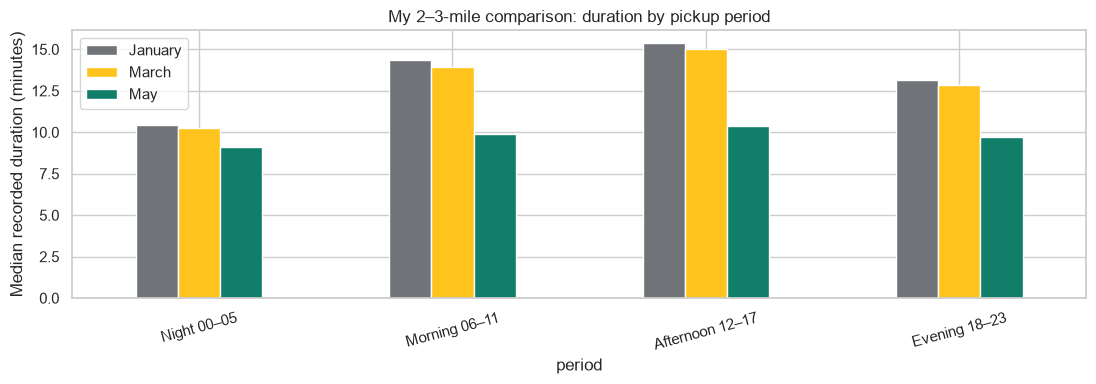

In [11]:
period_tables = {}
for month, view in comparison_views.items():
    period_tables[month] = view.groupby("period", observed=False).agg(
        records=("duration","size"), measured_durations=("duration","count"),
        median_minutes=("duration","median"), median_miles=("trip_distance","median"),
        flagged_duration_records=("flag_nonpositive_or_long_duration","sum"))
    print(month)
    display(period_tables[month])
period_medians = pd.DataFrame({month: table["median_minutes"] for month,table in period_tables.items()})
period_medians.plot.bar(figsize=(11,4), rot=15, color=["#707478","#FFC31D","#107E68"])
plt.ylabel("Median recorded duration (minutes)")
plt.title("My 2–3-mile comparison: duration by pickup period")
plt.tight_layout();plt.show()


### Pickup-time findings
Among 2–3-mile records, March's median recorded duration is **15.00 minutes in the afternoon (n=159,893)** versus **10.25 minutes overnight (n=36,698)**, a **4.75-minute gap**. Median distances are 2.38 and 2.40 miles. May's corresponding gap is about **1.22 minutes** (10.35 versus 9.13). These differences suggest that pickup time is useful to investigate. However, routes and traffic may also affect the results. All original rows are kept, and flagged finite durations are included in this comparison.

### Pickup-zone comparison
I restrict this comparison view to 2–3-mile records picked up from 10:00 to 15:59. I show the six highest-volume March pickup zones, with record counts and median recorded distance. Using the same daytime window makes the comparison more focused. Other differences between trips can still affect the results. All original rows are kept, and flagged finite durations are included.


Location names come from matching `PULocationID` to `LocationID` in the official TLC zone lookup table. These files contain pickup and drop-off zone IDs, not latitude and longitude. This analysis uses pickup zones; it does not recover exact pickup points, drop-off points, or routes.

,zone,records,median_minutes,median_miles,flagged_duration_records
PULocationID,,,,,
236,Upper East Side North,7624,15.150000,2.32,13
161,Midtown Center,6679,17.316667,2.35,12
237,Upper East Side South,6393,15.950000,2.36,8
239,Upper West Side South,5669,14.350000,2.31,15
142,Lincoln Square East,5549,14.183333,2.32,18
238,Upper West Side North,5142,14.350000,2.40,12


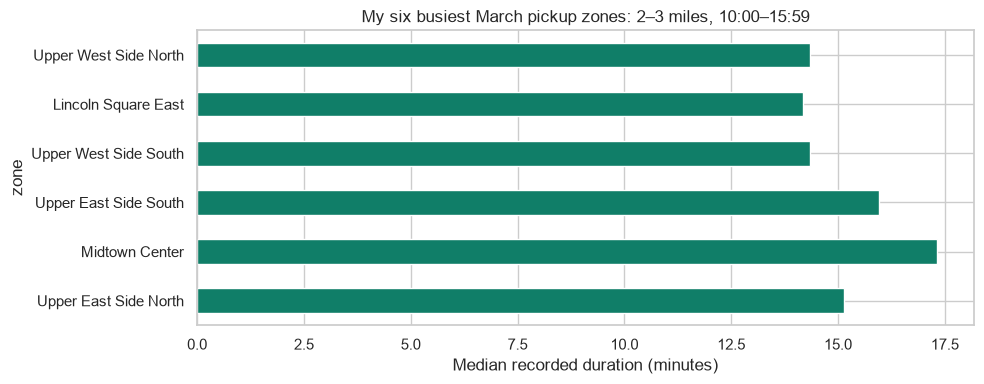

In [12]:
from urllib.request import urlretrieve
lookup_path = PATTERN_DATA_DIR / "taxi_zone_lookup.csv"
if not lookup_path.exists():
    urlretrieve("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv", lookup_path)
zone_lookup = pd.read_csv(lookup_path).set_index("LocationID")
march_daytime = comparison_views["March"].loc[comparison_views["March"]["hour"].between(10,15)]
zone_all = march_daytime.groupby("PULocationID").agg(
    records=("duration","size"), median_minutes=("duration","median"),
    median_miles=("trip_distance","median"), flagged_duration_records=("flag_nonpositive_or_long_duration","sum"))
zone_comparison = zone_all.sort_values("records", ascending=False).head(6).copy()
zone_comparison["zone"] = zone_comparison.index.map(zone_lookup["Zone"])
display(zone_comparison[["zone","records","median_minutes","median_miles","flagged_duration_records"]])
zone_comparison.set_index("zone")["median_minutes"].plot.barh(figsize=(10,4), color="#107E68")
plt.xlabel("Median recorded duration (minutes)")
plt.title("My six busiest March pickup zones: 2–3 miles, 10:00–15:59")
plt.tight_layout();plt.show()


### Pickup-zone findings
For March's 2–3-mile records picked up between 10:00 and 15:59, Midtown Center has a median recorded duration of **17.32 minutes (n=6,679)** and Lincoln Square East **14.18 minutes (n=5,549)**, a difference of about **3.13 minutes**. Their median distances are 2.35 and 2.32 miles. The six zones shown are the busiest in this comparison group, selected by volume rather than duration. Flagged finite durations are included.

This suggests pickup zone may add useful information. It does not prove that the pickup zone causes the difference. Destinations, routes, exact pickup times, and distances can still differ. I would test estimated distance, planned route, pickup hour, and pickup zone in a future prediction study.

Sources: NYC TLC monthly files and the [official zone lookup](https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv). No source rows are deleted.

## 10. Sensitivity check: handling invalid measurements
I preserve every original record. For this separate correlation check, I mark zero, negative, or infinite durations and negative or infinite distances as unavailable using `where`. This leaves the rows intact. Correlation uses the available measurement pairs; genuine long rides remain included. Zero distance is retained because it is not automatically proof of an error.

In [13]:
sensitivity_source = pd.read_parquet(DATA_DIR / "yellow_tripdata_2020-03.parquet", columns=["tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance"])
sensitivity_duration = (pd.to_datetime(sensitivity_source["tpep_dropoff_datetime"], errors="coerce") - pd.to_datetime(sensitivity_source["tpep_pickup_datetime"], errors="coerce")).dt.total_seconds() / 60
sensitivity_distance = sensitivity_source["trip_distance"]
valid_duration = sensitivity_duration.where(np.isfinite(sensitivity_duration) & sensitivity_duration.gt(0))
valid_distance = sensitivity_distance.where(np.isfinite(sensitivity_distance) & sensitivity_distance.ge(0))
raw_rho = pd.DataFrame({"distance": sensitivity_distance, "duration": sensitivity_duration}).corr(method="spearman").iloc[0, 1]
valid_rho = pd.DataFrame({"distance": valid_distance, "duration": valid_duration}).corr(method="spearman").iloc[0, 1]
assert len(valid_duration) == len(sensitivity_source)
print(f"All March source rows retained: {len(sensitivity_source):,}")
print(f"Nonpositive durations: {sensitivity_duration.le(0).sum():,}")
print(f"Available pairs for sensitivity calculation: {(valid_distance.notna() & valid_duration.notna()).sum():,}")
print(f"Raw recorded-value Spearman: {raw_rho:.9f}")
print(f"Positive-duration sensitivity Spearman: {valid_rho:.9f}")


All March source rows retained: 3,007,687
Nonpositive durations: 2,131
Available pairs for sensitivity calculation: 3,005,556
Raw recorded-value Spearman: 0.847029622
Positive-duration sensitivity Spearman: 0.846954637


### Sensitivity-check findings
I identified **2,131 nonpositive durations**, while preserving all **3,007,687 March rows**. The sensitivity calculation uses **3,005,556 available pairs**. Both the raw recorded-value Spearman correlation and the positive-duration sensitivity correlation round to **0.847**. The correlation changes very little in this check. This does not mean that every measurement is correct or that other statistics would stay the same.

## 11. Processing audit and workflow
This small Apache Beam example checks the source and retained row counts for each month. It uses the full-dataset counts calculated above; it does not reprocess every taxi record in Beam. The assertions confirm that no source rows were removed.

The GraphViz diagram summarizes the analysis workflow. Numeric preparation and the sensitivity check use separate copies, while the original records remain available.

,month,source_rows,retained_rows,removed_rows
2,January,6405008,6405008,0
0,March,3007687,3007687,0
1,May,348415,348415,0


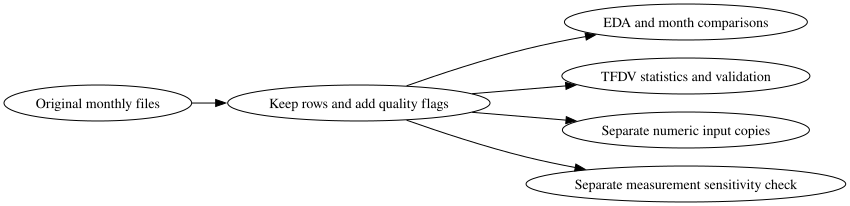

In [14]:
import apache_beam as beam
import tempfile
import json
from graphviz import Digraph

audit_records = [{"month": month, "source_rows": source_counts[month], "retained_rows": len(frame)}
                 for month, frame in records.items()]
with tempfile.TemporaryDirectory() as audit_directory:
    audit_prefix = str(Path(audit_directory) / "retention")
    with beam.Pipeline() as pipeline:
        (pipeline
         | "Read monthly audit counts" >> beam.Create(audit_records)
         | "Calculate removed rows" >> beam.Map(lambda item: dict(item, removed_rows=item["source_rows"] - item["retained_rows"]))
         | "Encode audit records" >> beam.Map(json.dumps)
         | "Write audit results" >> beam.io.WriteToText(audit_prefix, shard_name_template=""))
    beam_audit = pd.DataFrame([json.loads(line) for line in Path(audit_prefix).read_text().splitlines()])
assert beam_audit["removed_rows"].eq(0).all()
display(beam_audit.sort_values("month"))

workflow = Digraph("taxi_analysis")
workflow.attr(rankdir="LR")
workflow.node("source", "Original monthly files")
workflow.node("flags", "Keep rows and add quality flags")
workflow.node("eda", "EDA and month comparisons")
workflow.node("tfdv", "TFDV statistics and validation")
workflow.node("numeric", "Separate numeric input copies")
workflow.node("sensitivity", "Separate measurement sensitivity check")
workflow.edges([("source","flags"),("flags","eda"),("flags","tfdv"),("flags","numeric"),("flags","sensitivity")])
display(workflow)
